# Lesson 8 · The EDA Playbook: Exploring Any Unfamiliar Dataset
### A repeatable routine from 'what is this?' to 'here is what a model could learn from it'

| | |
|---|---|
| **Type** | LESSON 08 |
| **Time** | about 180 minutes |
| **Level** | Intermediate |
| **Prerequisites** | Lessons 1–7 |

**By the end of this notebook you will be able to:**

- Run an 8-step EDA routine on a dataset you have never seen
- Describe distributions, skew and outliers, and tell an *error* from a *legitimate extreme*
- Find relationships between numeric, categorical and mixed variables
- Detect confounding by stratifying, and avoid mistaking correlation for causation
- Identify trends, seasonality and autocorrelation in a time series
- Turn observations into testable **hypotheses**, and produce an **ML-readiness** assessment

## 🛠️ Setup
Run this cell first. It imports the tools and loads the data every problem below relies on.

In [1]:

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from course_utils import DATA_DIR, check, check_plot, first_look

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 100})
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)

dairy = pd.read_csv(DATA_DIR / "dairy_farms.csv")        # NEW, unfamiliar data: a survey of 1,200 dairy farms
prices = pd.read_csv(DATA_DIR / "market_prices_clean.csv", parse_dates=["date"])
print("Setup complete ✔  dairy", dairy.shape, "| prices", prices.shape)


Setup complete ✔  dairy (1200, 15) | prices (15048, 9)


## 👋 The day you meet a dataset you've never seen

Someone drops a file on your desk and says: *"Here's some data. Tell me what's interesting, and whether we can build a model from it."*
No documentation. No hints. This is the real job. Everything you learned in Lessons 1–7 was a **tool**; today you learn the **craft**.

> Exploratory Data Analysis (EDA) is *detective work, not a checklist.* But great detectives have a **routine** so they never skip the boring clue that solves the case.

## The EDA playbook: 8 steps

| # | Step | The question you're answering | Main tools |
|---|---|---|---|
| **0** | **Ask** | What is this data *for*? What decisions or models might it feed? | reading, the data owner |
| **1** | **Look** | What's in the table? | `shape`, `info`, `head/sample`, `dtypes` |
| **2** | **Audit** | Can I trust it? | missing, duplicates, validity, consistency, cross-column logic |
| **3** | **Describe** | What does each variable look like *alone*? | `describe`, histograms, `skew`, `value_counts` |
| **4** | **Relate** | How do variables move together? | scatter, box, heatmap, correlation, crosstab |
| **5** | **Control** | Is a relationship real, or is a third variable causing it? | stratify, colour by group |
| **6** | **Hunt** | What's unusual: error or discovery? | IQR, z-score, domain rules |
| **7** | **Trend** *(if time exists)* | How does it change over time? | resample, rolling, seasonality, autocorrelation |
| **8** | **Conclude** | What are my *hypotheses*, and is the data **ready for ML**? | hypothesis table, ML checklist |

We'll walk steps 0–6 and 8 on a **brand-new dairy-farm dataset** (cross-sectional), then step 7 on our market prices (time series). Watch my *thinking*; then in the project you do it on your own.

## Step 0 · Ask

**Context.** A dairy cooperative surveyed 1,200 farms. Nobody wrote a data dictionary. From the column names we *infer* meaning (and later **verify** it):

| Column | Probable meaning |
|---|---|
| `farm_id` | unique farm identifier |
| `county` | location |
| `herd_size`, `lactating_cows` | cows owned; cows currently milking |
| `breed`, `feed_system` | cow breed; how cows are fed |
| `farm_acres`, `annual_rainfall_mm` | land and climate |
| `vet_visits_per_year`, `farmer_age`, `has_cooling` | management & farmer traits (0/1 for cooling tank) |
| `milk_per_cow_l_day`, `total_milk_l_day` | productivity |
| `price_kes_per_litre`, `monthly_revenue_kes` | economics |

**Questions I'd like answered:** *What drives milk yield per cow? What explains revenue? Is there an opportunity for the co-op (feed advice? cooling tanks?). Could we predict yield or revenue?*

Writing the questions *first* keeps you from wandering. Now, look.

## Step 1 · Look

In [2]:
first_look(dairy)

📐 Shape: 1,200 rows × 15 columns
🔁 Fully duplicated rows: 0


,dtype,missing,missing_%,unique
farm_id,str,0,0.0,1200
county,str,0,0.0,8
herd_size,int64,0,0.0,26
lactating_cows,int64,0,0.0,20
breed,str,0,0.0,8
feed_system,str,0,0.0,3
farm_acres,float64,0,0.0,152
annual_rainfall_mm,float64,44,3.7,608
vet_visits_per_year,int64,0,0.0,11
farmer_age,float64,36,3.0,58


,farm_id,county,herd_size,lactating_cows,breed,feed_system,farm_acres,annual_rainfall_mm,vet_visits_per_year,farmer_age,has_cooling,milk_per_cow_l_day,total_milk_l_day,price_kes_per_litre,monthly_revenue_kes
0,F0001,Nyeri,2,2,Friesian,Silage + dairy meal,3.0,1250.0,2,65.0,1,12.7,25.5,43.3,33124.0
1,F0002,Nakuru,3,2,Friesian,Napier + dairy meal,5.7,913.0,0,68.0,0,11.0,22.1,39.1,25923.0
2,F0003,Nyandarua,3,2,Crossbreed,Napier + dairy meal,4.5,1045.0,5,52.0,0,6.4,12.8,39.3,15091.0
3,F0004,Nyandarua,4,3,Crossbreed,Napier only,4.0,1053.0,3,61.0,0,7.6,22.7,36.0,24516.0
4,F0005,Nakuru,7,5,Ayrshire,Napier only,7.4,994.0,2,41.0,0,7.4,36.8,40.5,44712.0


In [3]:
num_cols = dairy.select_dtypes("number").columns.tolist()
cat_cols = dairy.select_dtypes(exclude="number").columns.tolist()
print("numeric    :", num_cols)
print("categorical:", cat_cols)
print("\ncardinality of categoricals:", {c: dairy[c].nunique() for c in cat_cols})
print("\nis farm_id unique?", dairy["farm_id"].is_unique)

numeric    : ['herd_size', 'lactating_cows', 'farm_acres', 'annual_rainfall_mm', 'vet_visits_per_year', 'farmer_age', 'has_cooling', 'milk_per_cow_l_day', 'total_milk_l_day', 'price_kes_per_litre', 'monthly_revenue_kes']
categorical: ['farm_id', 'county', 'breed', 'feed_system']

cardinality of categoricals: {'farm_id': 1200, 'county': 8, 'breed': 8, 'feed_system': 3}

is farm_id unique? True


**First impressions (write these down: they're your hypotheses about the *data*, not yet about the world):**
* 1,200 rows, 15 columns; `farm_id` is a pure identifier (no information; drop it before modelling).
* `has_cooling` is numeric but really a **yes/no category**.
* Missing values in `farmer_age`, `annual_rainfall_mm`, `price_kes_per_litre`.
* `breed` has more than 4 distinct labels: probably a casing problem.
* `milk_per_cow_l_day` × `lactating_cows` *should equal* `total_milk_l_day`: we can test that.

## Step 2 · Audit

### 2.1 Completeness & consistency

In [4]:
print(dairy[["farmer_age", "annual_rainfall_mm", "price_kes_per_litre"]].isna().mean().mul(100).round(1).astype(str) + " %")
print("\nbreed labels:", dairy["breed"].value_counts().to_dict())

farmer_age             3.0 %
annual_rainfall_mm     3.7 %
price_kes_per_litre    2.0 %
dtype: str

breed labels: {'Friesian': 410, 'Crossbreed': 354, 'Ayrshire': 296, 'Jersey': 126, 'friesian': 6, 'crossbreed': 4, 'ayrshire': 2, 'jersey': 2}


### 2.2 Validity: what's physically impossible?

In [5]:
print(dairy[num_cols].describe().T[["min", "50%", "max"]].round(1))
print("\nFarms with MORE lactating cows than cows owned:", (dairy["lactating_cows"] > dairy["herd_size"]).sum())
print("Largest milk_per_cow_l_day:", dairy["milk_per_cow_l_day"].max(), "(world-record cows give ~70-80 L)")

                        min      50%       max
herd_size               1.0      4.0      33.0
lactating_cows          1.0      3.0      25.0
farm_acres              0.5      4.4      29.1
annual_rainfall_mm    711.0   1153.0    2070.0
vet_visits_per_year     0.0      2.0      10.0
farmer_age             22.0     49.0      82.0
has_cooling             0.0      0.0       1.0
milk_per_cow_l_day      1.5     11.9     157.0
total_milk_l_day        2.7     31.3     314.0
price_kes_per_litre    33.3     40.7      48.8
monthly_revenue_kes  3750.0  37968.0  421074.0

Farms with MORE lactating cows than cows owned: 5
Largest milk_per_cow_l_day: 157.0 (world-record cows give ~70-80 L)


### 2.3 Cross-column logic: let redundant columns check each other

If `total = lactating × per-cow`, then a row where that fails has an error *somewhere*. This is one of the most powerful audit tricks: **derived columns are free witnesses.**

In [6]:
implied = dairy["milk_per_cow_l_day"] * dairy["lactating_cows"]
gap = (implied - dairy["total_milk_l_day"]).abs() / dairy["total_milk_l_day"]
suspect = dairy[gap > 0.10]
print("Rows where lactating × per-cow differs from the total by >10%:", len(suspect))
suspect[["farm_id", "herd_size", "lactating_cows", "milk_per_cow_l_day", "total_milk_l_day"]].head(8)

Rows where lactating × per-cow differs from the total by >10%: 13


,farm_id,herd_size,lactating_cows,milk_per_cow_l_day,total_milk_l_day
22,F0023,3,2,101.0,20.1
151,F0152,5,8,5.8,17.3
279,F0280,4,3,139.0,41.6
296,F0297,6,9,7.7,30.7
325,F0326,2,1,72.0,7.2
351,F0352,13,8,157.0,125.7
374,F0375,1,4,11.7,11.7
629,F0630,4,3,91.0,27.4


> 🧠 **Pause and predict.** Look at those rows. In some, `milk_per_cow` is ~10× too big (a decimal slip) while `lactating_cows` is fine. In others, `lactating_cows` exceeds `herd_size` while `milk_per_cow` looks normal. Which column is wrong in each case? *The one that violates common sense.*

### 2.4 Repair, with a documented rule per problem

In [7]:
d = dairy.copy()

# (a) consistency: casing of breed
d["breed"] = d["breed"].str.title()

# (b) logic repairs
bad_lact = d["lactating_cows"] > d["herd_size"]                  # lactating count is wrong -> rebuild from total / per-cow
fix_pc = (gap > 0.10) & ~bad_lact                                # per-cow figure is wrong  -> rebuild from total / lactating
d.loc[fix_pc, "milk_per_cow_l_day"] = (d["total_milk_l_day"] / d["lactating_cows"])[fix_pc].round(1)
d.loc[bad_lact, "lactating_cows"] = (d["total_milk_l_day"] / d["milk_per_cow_l_day"])[bad_lact].round().astype(int)
print(f"repaired per-cow: {int(fix_pc.sum())} rows | repaired lactating count: {int(bad_lact.sum())} rows")

# (c) missing values: flag, then impute with a sensible group value
for col, by in [("farmer_age", None), ("annual_rainfall_mm", "county"), ("price_kes_per_litre", "county")]:
    d[col + "_was_missing"] = d[col].isna()
    fill = d[col].median() if by is None else d.groupby(by)[col].transform("median")
    d[col] = d[col].fillna(fill)

assert (d["lactating_cows"] <= d["herd_size"]).all() and d["milk_per_cow_l_day"].max() < 40
print("Remaining missing:", int(d[["farmer_age", "annual_rainfall_mm", "price_kes_per_litre"]].isna().sum().sum()),
      "| max milk per cow now:", d["milk_per_cow_l_day"].max())

repaired per-cow: 8 rows | repaired lactating count: 5 rows
Remaining missing: 0 | max milk per cow now: 21.5


> 🌍 **In the real world.** Notice the *reasoning*: we didn't blindly delete 13 rows or cap values: we used the relationship among columns to decide which number was wrong and rebuilt it. That's what 'domain knowledge + data logic' looks like.

## Step 3 · Describe each variable alone (univariate)

### 3.1 Numeric variables: centre, spread, **shape**

In [8]:
num = ["herd_size", "farm_acres", "annual_rainfall_mm", "vet_visits_per_year", "farmer_age",
       "milk_per_cow_l_day", "price_kes_per_litre", "monthly_revenue_kes"]
desc = d[num].describe().T
desc["skew"] = d[num].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
herd_size,1200.0,4.63,3.33,1.0,2.0,4.0,6.0,33.0,2.67
farm_acres,1200.0,5.13,3.39,0.5,2.8,4.4,6.4,29.1,2.03
annual_rainfall_mm,1200.0,1194.86,249.31,711.0,1021.5,1153.5,1299.0,2070.0,1.36
vet_visits_per_year,1200.0,2.42,1.60,0.0,1.0,2.0,3.0,10.0,0.81
farmer_age,1200.0,49.03,10.79,22.0,42.0,49.0,56.0,82.0,0.12
milk_per_cow_l_day,1200.0,11.87,3.17,1.5,9.7,11.8,14.1,21.5,-0.04
price_kes_per_litre,1200.0,40.80,2.66,33.3,38.9,40.7,42.6,48.8,0.14
monthly_revenue_kes,1200.0,49211.93,41539.64,3750.0,21585.0,37968.0,61800.0,421074.0,2.72


**Skewness** quantifies asymmetry: `≈ 0` symmetric, `> 0.5` right-skewed (long tail of big values), `< −0.5` left-skewed. Rule of thumb: *|skew| > 1 = strongly skewed.*

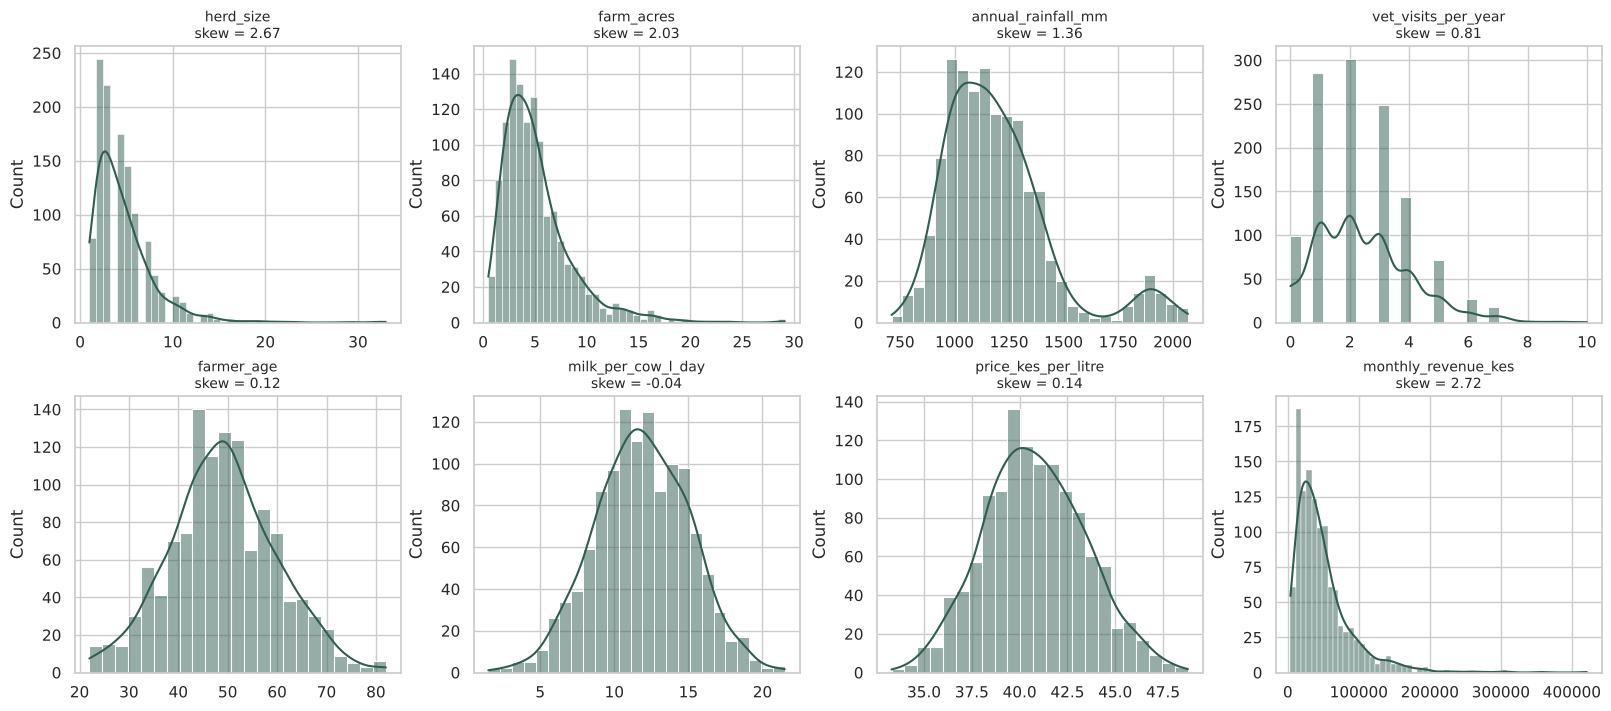

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for ax, col in zip(axes.flat, num):
    sns.histplot(d[col], kde=True, ax=ax, color="#2F5D50")
    ax.set_title(f"{col}\nskew = {d[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
plt.show()

**Reading the shapes:**
* `herd_size`, `farm_acres`, `monthly_revenue_kes`: **right-skewed** (most farms small, a few huge). Means mislead; medians describe the typical farm.
* `milk_per_cow_l_day`, `price_kes_per_litre`, `farmer_age`: roughly **bell-shaped**. `annual_rainfall_mm` has a right tail because one county (Kericho) is far wetter than the rest: it is really a *mixture of county-level bumps*.
* `vet_visits_per_year`: **counts** (0, 1, 2…), so it's discrete and a bit skewed.

Right-skewed positives often become symmetric after a **log transform**: which tames big values and is kinder to many models:

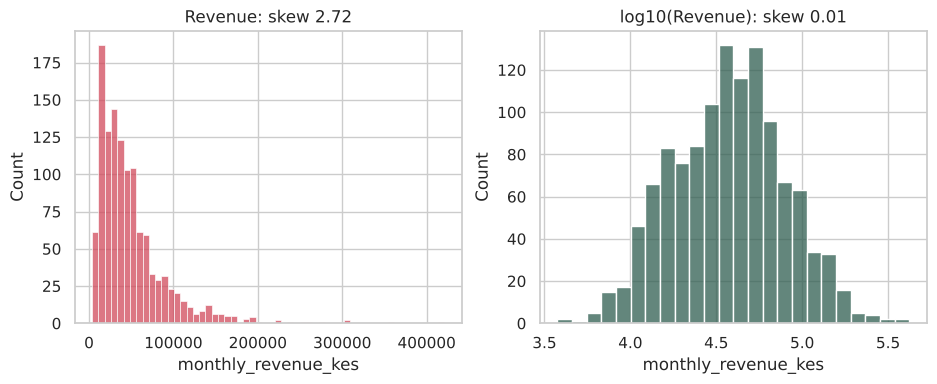

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(d["monthly_revenue_kes"], ax=axes[0], color="#d1495b");              axes[0].set_title(f"Revenue: skew {d['monthly_revenue_kes'].skew():.2f}")
sns.histplot(np.log10(d["monthly_revenue_kes"]), ax=axes[1], color="#2F5D50");     axes[1].set_title(f"log10(Revenue): skew {np.log10(d['monthly_revenue_kes']).skew():.2f}")
plt.show()

### 3.2 Categorical variables: balance and rarity

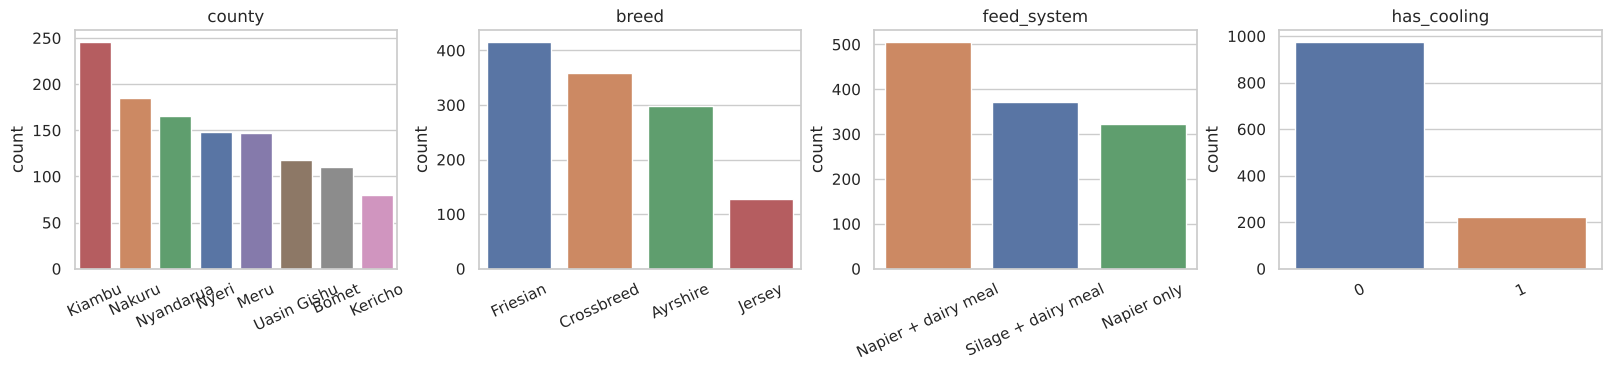

{0: 81.3, 1: 18.7} <- % of farms without / with a cooling tank


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), constrained_layout=True)
for ax, col in zip(axes, ["county", "breed", "feed_system", "has_cooling"]):
    order = d[col].value_counts().index
    sns.countplot(data=d, x=col, order=order, hue=col, legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
plt.show()
print((d["has_cooling"].value_counts(normalize=True) * 100).round(1).to_dict(), "<- % of farms without / with a cooling tank")

> 🤖 **Why machine learning cares.** Class balance matters: if fewer than one farm in five has a cooling tank, a model that always says 'no cooling' is >80% accurate and useless. We'll flag that in step 8.

## Step 4 · Relate variables (bivariate)

Choose the tool by the *type pair*:

| X \ Y | numeric Y | categorical Y |
|---|---|---|
| **numeric X** | scatter, correlation | box/violin of X by Y |
| **categorical X** | box/violin/bar of Y by X | `crosstab`, stacked bars, heatmap |

### 4.1 Numeric × numeric: the correlation heatmap

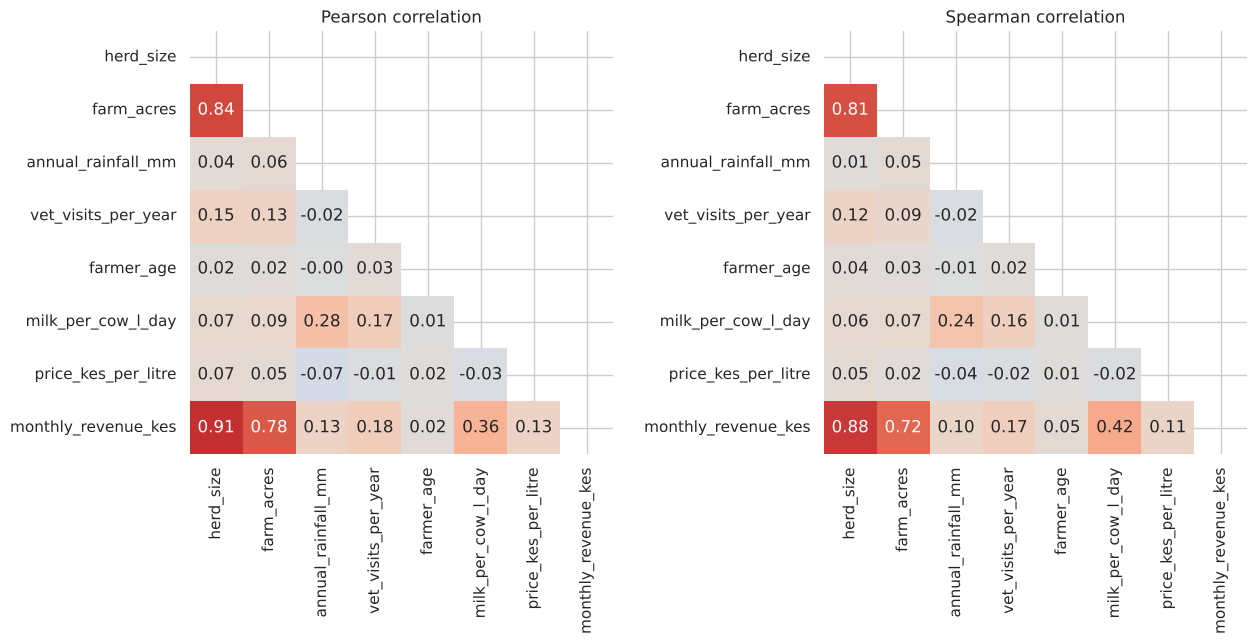

In [12]:
cols = ["herd_size", "farm_acres", "annual_rainfall_mm", "vet_visits_per_year", "farmer_age",
        "milk_per_cow_l_day", "price_kes_per_litre", "monthly_revenue_kes"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = d[cols].corr(method=method)
    sns.heatmap(c, mask=np.triu(np.ones_like(c, dtype=bool)), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
                cbar=False, square=True, ax=ax)
    ax.set_title(f"{method.title()} correlation")
plt.show()

**Pearson vs Spearman.** Pearson measures *straight-line* association and is dragged around by extreme values; **Spearman** correlates the *ranks*, so it captures any steadily rising/falling relationship and resists outliers.
For skewed variables like `herd_size` and revenue, the two can differ a lot: **if they disagree, plot the pair.**

Pearson: 0.91 | Spearman: 0.88


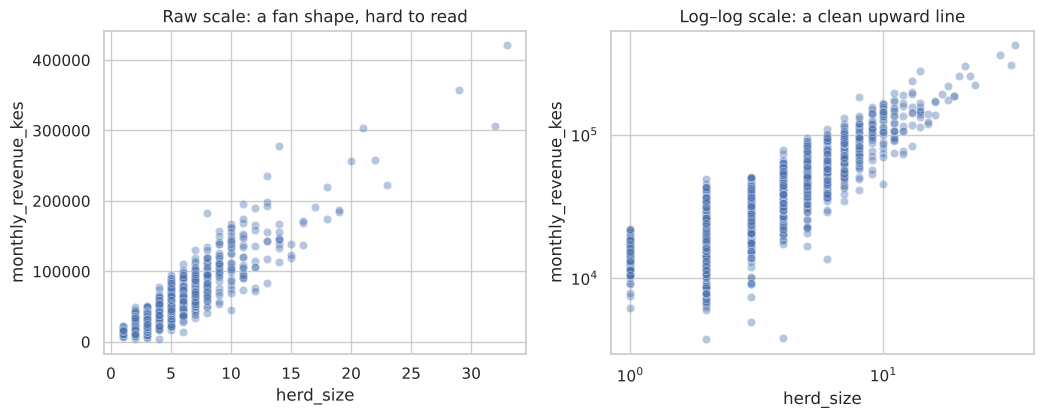

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.scatterplot(data=d, x="herd_size", y="monthly_revenue_kes", alpha=0.4, ax=axes[0]);  axes[0].set_title("Raw scale: a fan shape, hard to read")
sns.scatterplot(data=d, x="herd_size", y="monthly_revenue_kes", alpha=0.4, ax=axes[1]);  axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Log–log scale: a clean upward line")
print("Pearson:", round(d["herd_size"].corr(d["monthly_revenue_kes"]), 2), "| Spearman:", round(d["herd_size"].corr(d["monthly_revenue_kes"], method="spearman"), 2))
plt.show()

### 4.2 Categorical × numeric: compare groups

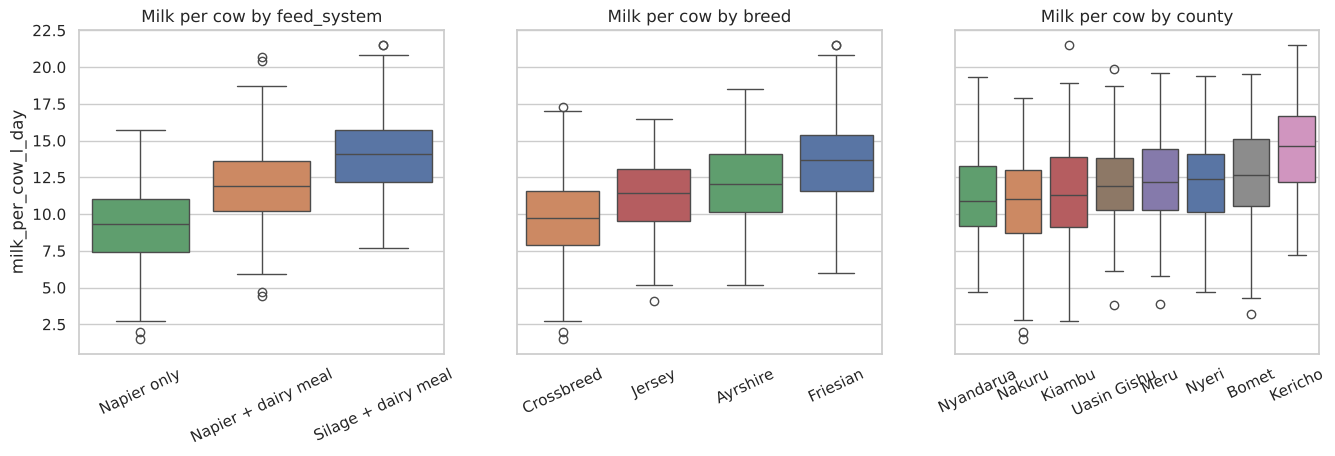

,farms,mean,median
feed_system,,,
Napier + dairy meal,506,11.94,11.9
Napier only,322,9.21,9.3
Silage + dairy meal,372,14.06,14.1


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, col in zip(axes, ["feed_system", "breed", "county"]):
    order = d.groupby(col)["milk_per_cow_l_day"].median().sort_values().index
    sns.boxplot(data=d, x=col, y="milk_per_cow_l_day", order=order, hue=col, legend=False, ax=ax)
    ax.set_title(f"Milk per cow by {col}"); ax.tick_params(axis="x", rotation=25); ax.set_xlabel("")
plt.show()
d.groupby("feed_system")["milk_per_cow_l_day"].agg(farms="count", mean="mean", median="median").round(2)

**Observations:** feed system separates yields cleanly (more feed → more milk); breed matters too (Friesian > Ayrshire > Jersey > Crossbreed); county shows little separation by comparison.
That is **evidence that feed and breed are strong candidate features, and county is probably weak for yield**: a hypothesis we'll test.

### 4.3 Categorical × categorical: who uses what?

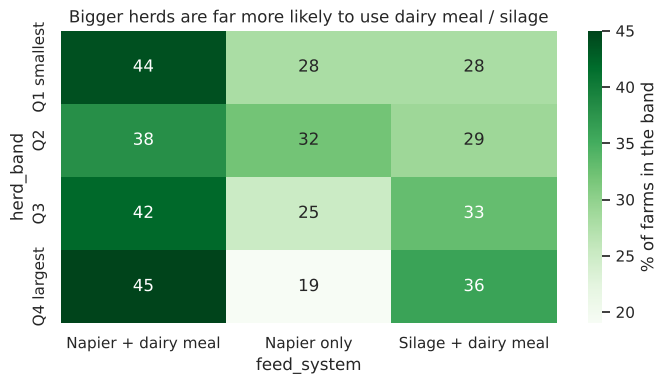

In [15]:
d["herd_band"] = pd.qcut(d["herd_size"], 4, labels=["Q1 smallest", "Q2", "Q3", "Q4 largest"])
share = pd.crosstab(d["herd_band"], d["feed_system"], normalize="index").mul(100).round(0)
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(share, annot=True, fmt=".0f", cmap="Greens", cbar_kws=dict(label="% of farms in the band"), ax=ax)
ax.set_title("Bigger herds are far more likely to use dairy meal / silage")
plt.show()

> 💡 **Intuition.** This one chart already warns you about the next step: **herd size and feed system are tangled together.** Anything that correlates with feed will also correlate with herd size.

## Step 5 · Control for a third variable (confounding)

> **Correlation is not causation**: but *why* not? Usually because of a **confounder**: a hidden variable that influences *both* things you're comparing.

### 5.1 Case study: do vet visits raise milk yield?

In [16]:
print("Overall correlation(vet visits, milk per cow):", round(d["vet_visits_per_year"].corr(d["milk_per_cow_l_day"]), 2))
print("Correlation(vet visits, herd size)           :", round(d["vet_visits_per_year"].corr(d["herd_size"]), 2))
print("Mean vet visits by feed system:\n", d.groupby("feed_system")["vet_visits_per_year"].mean().round(2).to_string())

Overall correlation(vet visits, milk per cow): 0.17
Correlation(vet visits, herd size)           : 0.15
Mean vet visits by feed system:
 feed_system
Napier + dairy meal    2.52
Napier only            1.84
Silage + dairy meal    2.79


Vet visits are somewhat higher on bigger, better-fed farms, and well-fed farms also produce more milk per cow. So *some* of the vet–yield association is the **feed system speaking through the vet variable**.
The tool: **stratify**: recompute the relationship *within* each feed group, where feed no longer varies.

Correlation WITHIN each feed system:
 feed_system
Napier + dairy meal    0.05
Napier only            0.00
Silage + dairy meal    0.09


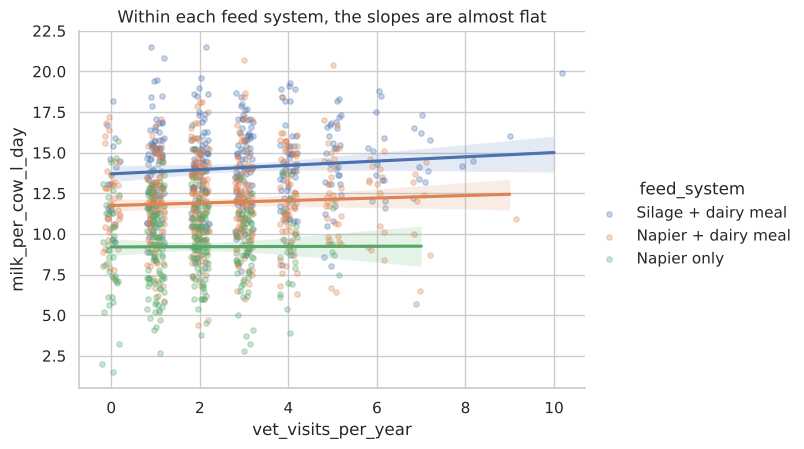

In [17]:
within = d.groupby("feed_system")[["vet_visits_per_year", "milk_per_cow_l_day"]].apply(lambda g: g["vet_visits_per_year"].corr(g["milk_per_cow_l_day"]))
print("Correlation WITHIN each feed system:\n", within.round(2).to_string())

sns.lmplot(data=d, x="vet_visits_per_year", y="milk_per_cow_l_day", hue="feed_system", height=4.5, aspect=1.4,
           scatter_kws=dict(alpha=0.3, s=15), x_jitter=0.2)
plt.title("Within each feed system, the slopes are almost flat")
plt.show()

> 🧠 **Pause and predict.** The pooled correlation (≈0.17) shrinks to about 0–0.09 inside each feed group: **most of the apparent vet effect was the feed system speaking through the vet variable.** Whatever small positive residue remains could be a modest real effect or another confounder (herd size? rainfall?). EDA can't settle causation; it tells you **what to control for** and **what experiment to run**.

### 5.2 Case study: do cooling tanks raise the milk price?

In [18]:
raw_gap = d.groupby("has_cooling")["price_kes_per_litre"].mean()
print("Raw gap (cooling − no cooling):", round(raw_gap[1] - raw_gap[0], 2), "KES/litre")

by_county = d.groupby(["county", "has_cooling"])["price_kes_per_litre"].mean().unstack()
by_county["gap"] = by_county[1] - by_county[0]
print("\nGap within each county:\n", by_county["gap"].round(2).to_string())
print("\nAverage within-county gap:", round(by_county["gap"].mean(), 2), "KES/litre")
print("Share of farms with cooling; Kiambu:", round(d.loc[d["county"] == "Kiambu", "has_cooling"].mean() * 100), "% | others:",
      round(d.loc[d["county"] != "Kiambu", "has_cooling"].mean() * 100), "%")

Raw gap (cooling − no cooling): 3.29 KES/litre

Gap within each county:
 county
Bomet          3.03
Kericho        2.96
Kiambu         2.38
Meru           2.91
Nakuru         3.35
Nyandarua      3.75
Nyeri          2.42
Uasin Gishu    3.64

Average within-county gap: 3.06 KES/litre
Share of farms with cooling; Kiambu: 29 % | others: 16 %


> 💡 **Intuition.** Cooling farms are over-represented in a **high-price county** (Kiambu), so the raw gap (≈3.3 KES/L) is a little inflated; within counties it is ≈3.1. Here the confounding is real but *small*, and **knowing that is a result**, not a disappointment. Never assume a confounder matters; stratify and measure it. This 'compare like with like' habit is the single most valuable instinct in analysis.

## Step 6 · Hunt for the unusual

Three complementary detectors:

| Detector | Flags | Weakness |
|---|---|---|
| **IQR rule** `x < Q1−1.5·IQR` or `x > Q3+1.5·IQR` | unusual *given the middle 50%* | flags many legitimate values in skewed data |
| **Z-score** `\|x−mean\|/sd > 3` | far from the mean | the mean/sd are themselves dragged by outliers |
| **Domain / logic rules** | impossible values | needs knowledge; catches what stats can't |

In [19]:
def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

report = pd.DataFrame({
    "IQR flags": {c: int(iqr_flags(d[c]).sum()) for c in num},
    "|z|>3 flags": {c: int(((d[c] - d[c].mean()).abs() / d[c].std() > 3).sum()) for c in num},
})
report

,IQR flags,|z|>3 flags
herd_size,35,18
farm_acres,58,22
annual_rainfall_mm,76,25
vet_visits_per_year,23,5
farmer_age,7,5
milk_per_cow_l_day,7,4
price_kes_per_litre,4,1
monthly_revenue_kes,66,20


`herd_size` and revenue have many IQR flags, but are they *errors*? A farm with 60 cows is unusual, not impossible. **An outlier is a question, not a verdict.**

In [20]:
big = d.nlargest(4, "herd_size")[["farm_id", "county", "herd_size", "lactating_cows", "milk_per_cow_l_day", "total_milk_l_day", "monthly_revenue_kes"]]
big

,farm_id,county,herd_size,lactating_cows,milk_per_cow_l_day,total_milk_l_day,monthly_revenue_kes
261,F0262,Nakuru,33,25,12.6,314.0,421074.0
111,F0112,Kericho,32,21,12.1,254.9,305880.0
1169,F1170,Meru,29,22,13.0,285.7,357411.0
757,F0758,Nyeri,23,19,9.6,182.7,222529.0


Check the *internal consistency* of each flagged row: big herds have proportionally big totals and revenues, and normal per-cow yields → **legitimate large farms**.
Contrast with the earlier 13 rows, which broke the arithmetic → **errors**. Our decision rule: *investigate extremes; remove only what is demonstrably wrong; keep the rest (they may be your most valuable customers).*

## Step 7 · Trends over time (a different dataset: market prices)

Cross-sectional data (dairy) has no time axis. Our market prices do. Four questions for any time series:

1. **Trend**: is it drifting up/down? 2. **Seasonality**: does a pattern repeat each year? 3. **Noise / shocks**: what's left, and are there spikes? 4. **Memory**: does today predict tomorrow (autocorrelation)?

We'll do a simple **additive decomposition by hand**: `price = trend + seasonal + residual`.

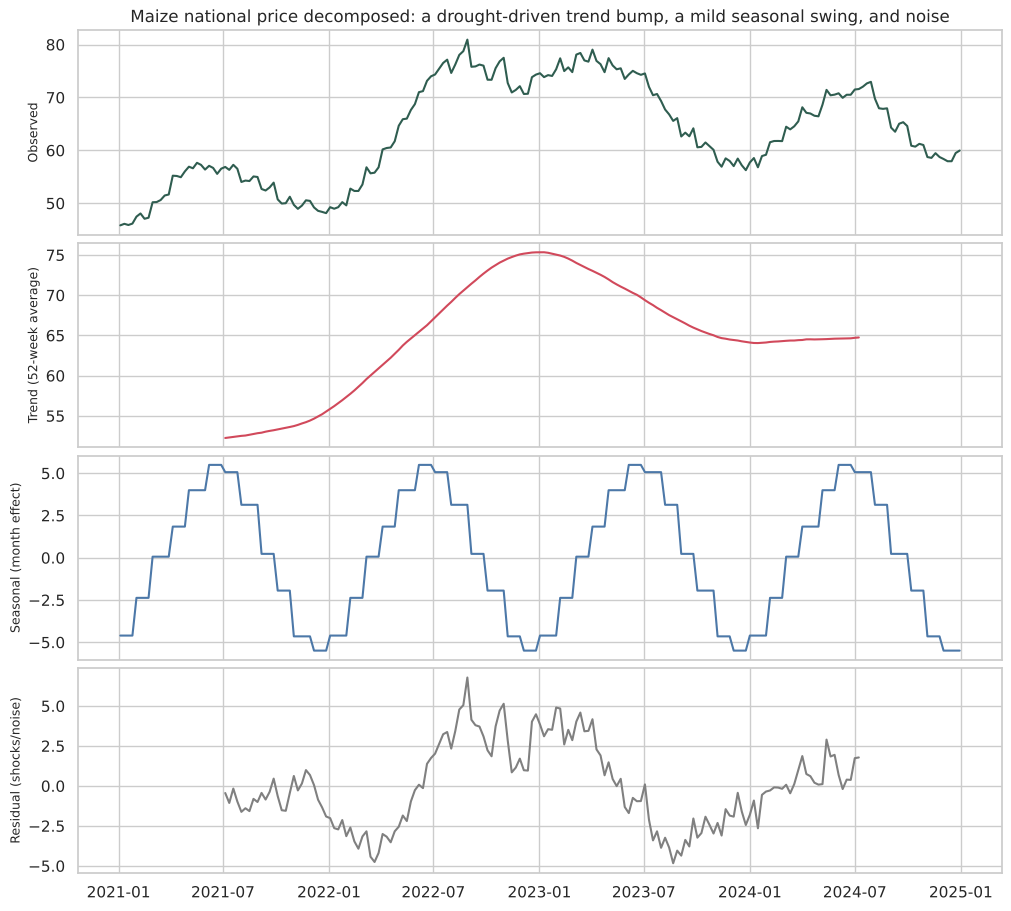

In [21]:
s = prices[prices["crop"] == "Maize"].groupby("date")["price_kes_per_kg"].mean()      # national weekly average
trend = s.rolling(52, center=True).mean()                                            # 1-year centred moving average
detrended = s - trend
seasonal = detrended.groupby(detrended.index.month).transform("mean")                # average wiggle for each calendar month
resid = s - trend - seasonal

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True, constrained_layout=True)
for ax, (name, series, color) in zip(axes, [("Observed", s, "#2F5D50"), ("Trend (52-week average)", trend, "#d1495b"),
                                          ("Seasonal (month effect)", seasonal, "#4c78a8"), ("Residual (shocks/noise)", resid, "grey")]):
    ax.plot(series.index, series.values, color=color); ax.set_ylabel(name, fontsize=9)
axes[0].set_title("Maize national price decomposed: a drought-driven trend bump, a mild seasonal swing, and noise")
plt.show()

In [22]:
print("Autocorrelation of the weekly price (how much does last week predict this week?)")
for lag in [1, 4, 13, 26, 52]:
    print(f"  lag {lag:>2} weeks: {s.autocorr(lag):.2f}")
print("\nAutocorrelation of week-to-week CHANGES:")
ch = s.diff().dropna()
for lag in [1, 2, 4]:
    print(f"  lag {lag} week(s): {ch.autocorr(lag):.2f}")
yoy = (s.groupby(s.index.year).mean().pct_change() * 100).round(1)
print("\nYear-on-year change in the average price (%):", yoy.dropna().to_dict())

Autocorrelation of the weekly price (how much does last week predict this week?)
  lag  1 weeks: 0.99
  lag  4 weeks: 0.96
  lag 13 weeks: 0.69
  lag 26 weeks: 0.27
  lag 52 weeks: -0.07

Autocorrelation of week-to-week CHANGES:
  lag 1 week(s): 0.00
  lag 2 week(s): -0.09
  lag 4 week(s): 0.32

Year-on-year change in the average price (%): {2022: 28.7, 2023: 3.2, 2024: -6.9}


> 🤖 **Why machine learning cares.** A lag-1 autocorrelation near 1 means *'next week ≈ this week'* is a very strong baseline forecast. Any ML model must **beat the naive baseline** to be worth deploying. Seasonality suggests month features; the trend bump suggests the model must cope with regime shifts (drought).

## Step 8 · Conclude: hypotheses and ML-readiness

### 8.1 Turn observations into testable hypotheses

A good hypothesis has four parts: **Observation → Hypothesis → How to test → What it means for ML.**

| Observation | Hypothesis | How to test | ML implication |
|---|---|---|---|
| Boxplots: yield rises with feed intensity | Dairy meal/silage raises yield by ≈ 2–5 L/cow/day | difference of means + bootstrap CI; control for breed | `feed_system` = strong feature |
| Cooling farms get higher prices; they cluster somewhat in Kiambu | Cooling raises price ≈ +3 KES/L even *within* a county | within-county gaps; later, regression with county dummies | include both `has_cooling` and `county` |
| Revenue spans orders of magnitude | Revenue ≈ cows × yield × price, so herd size dominates | log-log slope; variance decomposition | model `log(revenue)`; don't use raw scale |
| Maize prices lag-1 autocorrelation ≈ 1 | Naive "same as last week" is hard to beat | compare model error with naive error | always report a naive baseline |

Let's actually **test the first one**: is the feed effect distinguishable from chance? We bootstrap the difference in mean yield:

In [23]:
a = d.loc[d["feed_system"] == "Napier only", "milk_per_cow_l_day"].to_numpy()
b = d.loc[d["feed_system"] == "Napier + dairy meal", "milk_per_cow_l_day"].to_numpy()
rng = np.random.default_rng(0)
diffs = np.array([rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean() for _ in range(3000)])
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Observed difference: {b.mean() - a.mean():.2f} L/cow/day   95% bootstrap interval: [{lo:.2f}, {hi:.2f}]")
print("Interval excludes 0?", not (lo <= 0 <= hi))

Observed difference: 2.73 L/cow/day   95% bootstrap interval: [2.38, 3.10]
Interval excludes 0? True


### 8.2 The ML-readiness assessment

Suppose the co-op wants to **predict `milk_per_cow_l_day`** (a regression target). Walk each column and decide its role:

In [24]:
target = "milk_per_cow_l_day"
role = {
    "farm_id": "DROP: identifier, no information",
    "total_milk_l_day": "LEAKAGE: total = lactating × target",
    "monthly_revenue_kes": "LEAKAGE: derived from total_milk (and so from the target)",
}
tbl = pd.DataFrame({
    "dtype": d.dtypes.astype(str),
    "n_unique": d.nunique(),
    "skew": d.skew(numeric_only=True).round(2),
})
tbl = tbl.drop(index="herd_band")                                   # a helper column we created for a chart
tbl["role"] = [role.get(c, "TARGET" if c == target else "feature") for c in tbl.index]
tbl["prep needed"] = [
    "-" if r != "feature" else
    ("one-hot encode" if tbl.loc[c, "dtype"] in ("object", "str", "category") else
     ("binary: keep as 0/1" if tbl.loc[c, "n_unique"] == 2 else
      ("log-transform" if abs(tbl.loc[c, "skew"]) > 1 else "scale (if distance/linear model)")))
    for c, r in zip(tbl.index, tbl["role"])]
tbl.loc[~tbl.index.str.endswith("_was_missing")]

,dtype,n_unique,skew,role,prep needed
annual_rainfall_mm,float64,611,1.36,feature,log-transform
breed,str,4,NaN,feature,one-hot encode
county,str,8,NaN,feature,one-hot encode
farm_acres,float64,152,2.03,feature,log-transform
farm_id,str,1200,NaN,"DROP: identifier, no information",-
farmer_age,float64,58,0.12,feature,scale (if distance/linear model)
feed_system,str,3,NaN,feature,one-hot encode
has_cooling,int64,2,1.61,feature,binary: keep as 0/1
herd_size,int64,26,2.67,feature,log-transform
lactating_cows,int64,20,2.64,feature,log-transform


**Leakage** deserves its own warning: a column that is *computed from the target* (or only known after it happens) makes a model look brilliant in testing and useless in real life.
Always ask of each feature: *"Would I know this at the moment I need the prediction?"*

**Redundancy:** features that say the same thing (e.g. `herd_size` and `lactating_cows`) add little and can destabilise linear models:

In [25]:
fc = d[["herd_size", "lactating_cows", "farm_acres", "vet_visits_per_year", "annual_rainfall_mm", "farmer_age"]].corr()
pairs = fc.where(np.triu(np.ones(fc.shape, dtype=bool), 1)).stack()
print("Highly correlated feature pairs (|r| > 0.7):")
print(pairs[pairs.abs() > 0.7].round(2).to_string())

Highly correlated feature pairs (|r| > 0.7):
herd_size       lactating_cows    0.98
                farm_acres        0.84
lactating_cows  farm_acres        0.83


### 8.3 The ML-readiness checklist

| Check | Status for the dairy data |
|---|---|
| Clear target defined? | ✅ `milk_per_cow_l_day` (regression): or a *high-yield* label (classification) |
| Enough rows? | ✅ ~1,200; fine for simple models, modest for complex ones |
| Missing values handled & flagged? | ✅ imputed + `_was_missing` flags |
| Errors repaired / documented? | ✅ 13 logic repairs, casing fixed |
| Leakage removed? | ⚠️ drop `total_milk_l_day`, `monthly_revenue_kes` |
| Redundant features? | ⚠️ `herd_size` ≈ `lactating_cows` (r≈0.98) and `farm_acres` (r≈0.84) |
| Skewed features? | ⚠️ log-transform `herd_size`, `farm_acres` |
| Categoricals to encode? | ⚠️ `county`, `breed`, `feed_system` |
| Class balance (if classifying)? | ⚠️ only a minority (<1 in 5) have cooling |
| Naive baseline to beat? | ➕ predict the group mean by feed system |
| Confounders understood? | ✅ feed ↔ herd size ↔ vet visits |

### 8.4 Your EDA report skeleton (used again in the project)

1. **Overview**: source, rows × columns, period, unit of analysis, data dictionary.
2. **Data-quality assessment**: each issue found, how many rows, the decision taken.
3. **Descriptive statistics**: centre/spread/shape of key variables.
4. **Visual exploration**: distributions, comparisons, trends, relationships.
5. **Correlation analysis**: heatmap + stratified checks for confounding.
6. **Observations & hypotheses**: table (observation → hypothesis → test → ML implication).
7. **ML-readiness**: target candidates, leakage, features, prep steps, baseline.
8. **Limitations**: what the data *cannot* tell us.

---
# 🏋️ Problems

Variables from Setup: `dairy` (**raw**, unrepaired), `prices` (tidy). Where a problem says "repaired" or "clean", it tells you exactly what to do.

### 🧩 Problem 8.1: Which variable is most skewed?

Among `herd_size`, `farm_acres`, `vet_visits_per_year`, `farmer_age` in the raw `dairy` table, which has the **largest (positive) skewness**?

*Expected type:* a string (column name).

<details>
<summary>💡 Hint 1</summary>

`series.skew()` computes skewness; `DataFrame.skew()` does all numeric columns at once.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

Select the four columns, `.skew()`, then `.idxmax()`.

</details>

*Auto-check id:* `08-p1`  ·  *Set the variable `answer`, then run the cell.*

In [26]:
# ✍️ Your turn: compute the result and store it in `answer`
answer = None

check('08-p1', answer)

⏳ 08-p1: you haven't set `answer` yet. Read the problem, try it, then run this cell again.


False

### 🧩 Problem 8.2: Herd-size outliers by the IQR rule

Using the **IQR rule** (below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`, quartiles via `quantile`) on `dairy['herd_size']`, how many farms are flagged?

*Expected type:* integer.

<details>
<summary>💡 Hint 1</summary>

`q1, q3 = s.quantile([0.25, 0.75])`, `iqr = q3 - q1`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()`.

</details>

*Auto-check id:* `08-p2`  ·  *Set the variable `answer`, then run the cell.*

In [27]:
# ✍️ Your turn: compute the result and store it in `answer`
answer = None

check('08-p2', answer)

⏳ 08-p2: you haven't set `answer` yet. Read the problem, try it, then run this cell again.


False

### 🧩 Problem 8.3: Rows that break the arithmetic

In the raw `dairy` table, `milk_per_cow_l_day × lactating_cows` should (approximately) equal `total_milk_l_day`. Count the rows where the **relative difference** `|implied − total| / total` exceeds **0.10**.

*Expected type:* integer.

<details>
<summary>💡 Hint 1</summary>

Implied total = `dairy['milk_per_cow_l_day'] * dairy['lactating_cows']`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

Relative gap: `(implied - total).abs() / total`; count where it's `> 0.10`.

</details>

*Auto-check id:* `08-p3`  ·  *Set the variable `answer`, then run the cell.*

In [28]:
# ✍️ Your turn: compute the result and store it in `answer`
answer = None

check('08-p3', answer)

⏳ 08-p3: you haven't set `answer` yet. Read the problem, try it, then run this cell again.


False

### 🧩 Problem 8.4: Yield by feed system (excluding impossible values)

Drop rows from raw `dairy` where `milk_per_cow_l_day` is **greater than 40** (impossible values). Then return the **mean `milk_per_cow_l_day` for each `feed_system`** as a dictionary, rounded to 2 decimals.

*Expected type:* dict.

<details>
<summary>💡 Hint 1</summary>

Filter first with `dairy[dairy['milk_per_cow_l_day'] <= 40]`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`groupby('feed_system')['milk_per_cow_l_day'].mean().round(2).to_dict()`.

</details>

*Auto-check id:* `08-p4`  ·  *Set the variable `answer`, then run the cell.*

In [29]:
# ✍️ Your turn: compute the result and store it in `answer`
answer = None

check('08-p4', answer)

⏳ 08-p4: you haven't set `answer` yet. Read the problem, try it, then run this cell again.


False

### 🧩 Problem 8.5: Spearman: herd size and revenue

What is the **Spearman** rank correlation between `herd_size` and `monthly_revenue_kes` in raw `dairy`? Round to 3 decimals.

*Expected type:* float.

<details>
<summary>💡 Hint 1</summary>

`Series.corr` has a `method` argument.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`dairy['herd_size'].corr(dairy['monthly_revenue_kes'], method='spearman')`.

</details>

*Auto-check id:* `08-p5`  ·  *Set the variable `answer`, then run the cell.*

In [30]:
# ✍️ Your turn: compute the result and store it in `answer`
answer = None

check('08-p5', answer)

⏳ 08-p5: you haven't set `answer` yet. Read the problem, try it, then run this cell again.


False

### 🧩 Problem 8.6: The cooling effect, controlling for county

Compute, **within each county**, the difference in mean `price_kes_per_litre` between farms **with** (`has_cooling == 1`) and **without** (`== 0`) a cooling tank (ignore missing prices). Return the **simple average of these county gaps**, rounded to 2 decimals.

*Expected type:* float.

<details>
<summary>💡 Hint 1</summary>

`dairy.groupby(['county','has_cooling'])['price_kes_per_litre'].mean().unstack()` gives a county × (0/1) table.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

Gap = column `1` minus column `0`; then `.mean()` across counties.

</details>

*Auto-check id:* `08-p6`  ·  *Set the variable `answer`, then run the cell.*

In [31]:
# ✍️ Your turn: compute the result and store it in `answer`
answer = None

check('08-p6', answer)

⏳ 08-p6: you haven't set `answer` yet. Read the problem, try it, then run this cell again.


False

### 🧩 Problem 8.7: Year-on-year maize inflation

Compute the **national mean maize price** per calendar year (mean of all maize rows in `prices`). Return the **percentage change from 2022 to 2023**, rounded to 1 decimal.

*Expected type:* float.

<details>
<summary>💡 Hint 1</summary>

Filter maize, `groupby(prices['date'].dt.year)['price_kes_per_kg'].mean()`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`(y[2023] / y[2022] - 1) * 100`.

</details>

*Auto-check id:* `08-p7`  ·  *Set the variable `answer`, then run the cell.*

In [32]:
# ✍️ Your turn: compute the result and store it in `answer`
answer = None

check('08-p7', answer)

⏳ 08-p7: you haven't set `answer` yet. Read the problem, try it, then run this cell again.


False

### 🎨 Problem 8.8: Feed system and yield - a chart for the co-op

Using the raw `dairy` data **excluding** `milk_per_cow_l_day > 40`, draw a **box plot** of `milk_per_cow_l_day` for each `feed_system` (Seaborn). Title and axis labels with units are required.

<details>
<summary>💡 Hint 1</summary>

Filter first. `sns.boxplot(data=ok, x='feed_system', y='milk_per_cow_l_day', ax=ax)`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

Set the title to state the *finding* (e.g. which feed system gives the highest yield) and label the y-axis (litres per cow per day).

</details>

❌ 08-p8: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected at least 9 line(s) but found 0.


False

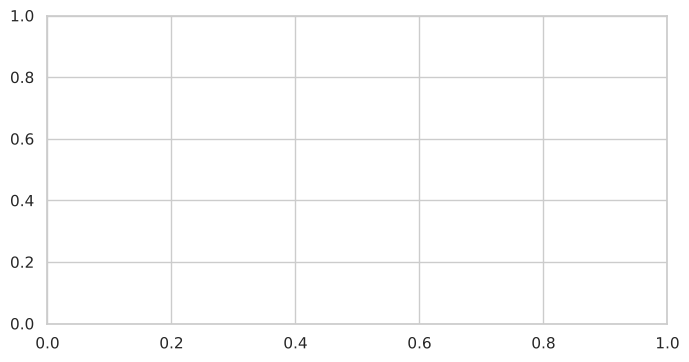

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_lines=9, name='08-p8')

### 🎨 Problem 8.9: Revenue vs herd size on a log–log scale

Draw a **scatter plot** of `herd_size` (x) against `monthly_revenue_kes` (y) for raw `dairy`, with **both axes on a log scale**, `alpha=0.4`, a title and axis labels.

<details>
<summary>💡 Hint 1</summary>

`sns.scatterplot(data=dairy, x='herd_size', y='monthly_revenue_kes', alpha=0.4, ax=ax)`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`ax.set_xscale('log')` and `ax.set_yscale('log')`.

</details>

❌ 08-p9: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected at least 1000 scatter points but found 0.

False

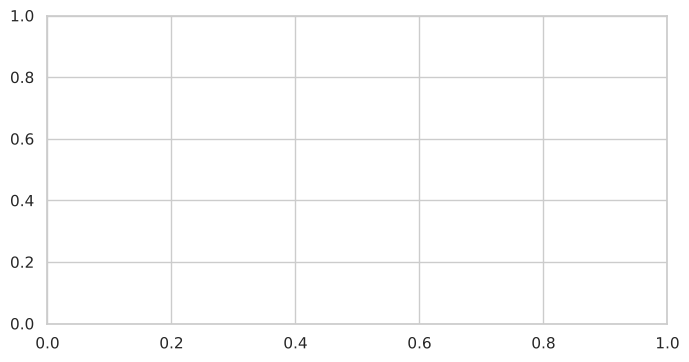

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_points=1000, name='08-p9')

### ✍️ Problem 8.10: Write two hypotheses

From the dairy EDA (or your own exploration of `dairy`), write **two hypotheses** in the four-part format *(Observation → Hypothesis → How to test → ML implication)*. One must involve a **confounder** you would control for.

✍️ *Write your answer here (double-click to edit):*



## ✅ Check your understanding

Answer in your head (or out loud!) first, *then* open the answer.

**Q1. Why can *derived columns* (like `total = lactating × per-cow`) be so valuable during the audit?**

<details>
<summary>Show answer</summary>

They are redundant witnesses: when the arithmetic fails you know a value is wrong, and the other columns often tell you *which one* and how to rebuild it.

</details>

**Q2. What's the difference between an outlier and an error?**

<details>
<summary>Show answer</summary>

An outlier is an *unusual but possibly real* value (a farm with 60 cows). An error is a *demonstrably wrong* value (more milking cows than owned). Investigate outliers; remove or repair errors.

</details>

**Q3. Describe how you would test whether a correlation is driven by a confounder.**

<details>
<summary>Show answer</summary>

Stratify: recompute the relationship within levels of the suspected confounder (or colour the scatter by it). If the association shrinks or reverses within groups, the confounder was doing the work.

</details>

**Q4. What is data leakage? Give an example from the dairy dataset.**

<details>
<summary>Show answer</summary>

Using information that wouldn't be available at prediction time, or that is computed from the target. Example: `total_milk_l_day` when predicting `milk_per_cow_l_day`.

</details>

**Q5. Why is a naive baseline ('next week = this week') important for time-series models?**

<details>
<summary>Show answer</summary>

Prices are highly autocorrelated, so the naive forecast is already very accurate. A model is only useful if it beats it.

</details>

## 🧾 Cheat-sheet: the playbook on one page

| Step | Do this |
|---|---|
| 0 Ask | write the questions, find/construct a data dictionary |
| 1 Look | `first_look(df)`, split numeric/categorical, check ID uniqueness |
| 2 Audit | missing, duplicates, `value_counts` of categories, `describe` min/max, cross-column logic |
| 3 Describe | hist + `skew()`, `value_counts(normalize=True)`; log-transform right-skewed variables |
| 4 Relate | corr heatmap (Pearson **and** Spearman), box by group, `crosstab` heatmap |
| 5 Control | stratify by the suspected confounder; colour by group |
| 6 Hunt | IQR + z-score + domain rules; *investigate before deleting* |
| 7 Trend | rolling mean, month profile, decomposition, autocorrelation, baseline |
| 8 Conclude | hypothesis table; leakage / redundancy / encoding / balance checklist |

## ➡️ Next up
**Lesson 9; The Capstone Project.** Everything comes together on the agricultural market dataset. You get a brief, a rubric, a scaffold, and a reference solution to compare against when you're done.